# Understanding Logistic Regression in Python (DataCamp Guide)
This notebook implements an end-to-end binary classification pipeline using **Logistic Regression** based on the DataCamp tutorial:
1. **Mathematical Background:** Sigmoid function and odds ratio
2. **Dataset:** Pima Indians Diabetes Database
3. **Exploratory Data Analysis & Feature Selection**
4. **Data Splitting (`train_test_split`)**
5. **Model Training (`LogisticRegression`)**
6. **Model Evaluation:** Confusion Matrix, Precision, Recall, and F1-Score
7. **ROC Curve & AUC Score**
8. **Sample Prediction & Class Probability Inference**

In [1]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Pima Indians Diabetes Dataset
The dataset predicts whether or not a patient has diabetes based on diagnostic measurements:
* **Features:** Number of pregnancies, glucose concentration, blood pressure, skin fold thickness, insulin level, BMI, diabetes pedigree function, and age.
* **Target (`label`):** `1` (positive for diabetes), `0` (negative).

In [2]:
col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

try:
    df = pd.read_csv(DATA_URL, header=None, names=col_names)
    print("✓ Dataset successfully fetched from remote source.")
except Exception:
    print("! Fetch failed. Generating synthetic sample matching dataset schema.")
    np.random.seed(42)
    synthetic_data = np.column_stack([
        np.random.randint(0, 15, 200),     # pregnant
        np.random.normal(120, 30, 200),    # glucose
        np.random.normal(70, 12, 200),     # bp
        np.random.normal(20, 10, 200),     # skin
        np.random.normal(80, 40, 200),     # insulin
        np.random.normal(32, 6, 200),      # bmi
        np.random.uniform(0.1, 1.5, 200),  # pedigree
        np.random.randint(21, 70, 200),    # age
        np.random.binomial(1, 0.35, 200)   # label
    ])
    df = pd.DataFrame(synthetic_data, columns=col_names)

print(f"Dataset Shape: {df.shape}")
df.head()

✓ Dataset successfully fetched from remote source.
Dataset Shape: (768, 9)


,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Exploratory Data Analysis & Class Balance
Examine target distribution and statistical summaries. An imbalanced class distribution affects metric interpretation (why precision and recall matter over raw accuracy).

Summary Statistics:


,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00



Class Distribution:
Non-Diabetic (0): 500 (65.1%)
Diabetic (1)    : 268 (34.9%)


/tmp/ipykernel_923/2307054521.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df, palette=['#3498db', '#e74c3c'])


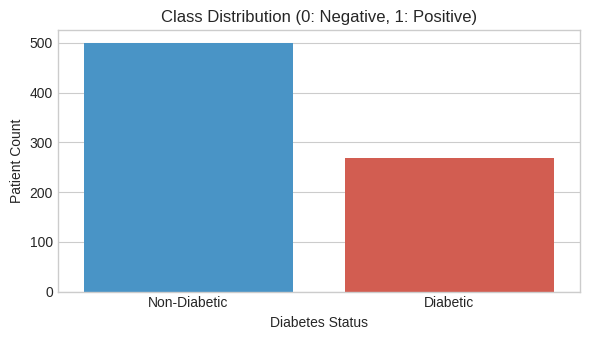

In [3]:
print("Summary Statistics:")
display(df.describe().round(2))

# Class balance check
class_counts = df['label'].value_counts()
print("\nClass Distribution:")
print(f"Non-Diabetic (0): {class_counts.get(0, 0)} ({class_counts.get(0, 0) / len(df) * 100:.1f}%)")
print(f"Diabetic (1)    : {class_counts.get(1, 0)} ({class_counts.get(1, 0) / len(df) * 100:.1f}%)")

# Visualize target distribution
plt.figure(figsize=(6, 3.5))
sns.countplot(x='label', data=df, palette=['#3498db', '#e74c3c'])
plt.title("Class Distribution (0: Negative, 1: Positive)", fontsize=12)
plt.xlabel("Diabetes Status")
plt.ylabel("Patient Count")
plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.tight_layout()
plt.show()

## 3. Feature Selection & Train/Test Split
As in the DataCamp guide, select predictive diagnostic features and partition the data into **75% training** and **25% testing** sets.

In [4]:
# Selected feature columns
feature_cols = ['pregnant', 'insulin', 'bmi', 'age', 'glucose', 'bp', 'pedigree']
X = df[feature_cols]
y = df['label']

# Split data (random_state=16 for reproducibility)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=16
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Testing set : {X_test.shape[0]} rows")

Training set: 576 rows
Testing set : 192 rows


## 4. Model Training: Logistic Regression
Logistic Regression models the probability $P(Y=1)$ using the sigmoid (logistic) function:
$$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$
where $z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n$.

In [5]:
# max_iter increased to ensure gradient convergence
logreg = LogisticRegression(max_iter=1000, random_state=16)
logreg.fit(X_train, y_train)

# Inspect model coefficients
coeff_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': logreg.coef_[0].round(4)
}).sort_values(by='Coefficient', ascending=False)

print(f"Intercept: {logreg.intercept_[0]:.4f}\n")
print("Learned Feature Coefficients:")
display(coeff_df)

Intercept: -7.7686

Learned Feature Coefficients:


,Feature,Coefficient
6,pedigree,0.8033
0,pregnant,0.0908
2,bmi,0.0907
4,glucose,0.0324
3,age,0.0128
1,insulin,-0.0013
5,bp,-0.0136


## 5. Model Evaluation: Confusion Matrix & Classification Metrics
Generate discrete predictions on test observations and construct a Confusion Matrix:
* **True Positives (TP):** Correctly predicted diabetic.
* **True Negatives (TN):** Correctly predicted non-diabetic.
* **False Positives (FP) (Type I Error):** Non-diabetic wrongly predicted as diabetic.
* **False Negatives (FN) (Type II Error):** Diabetic wrongly predicted as non-diabetic.

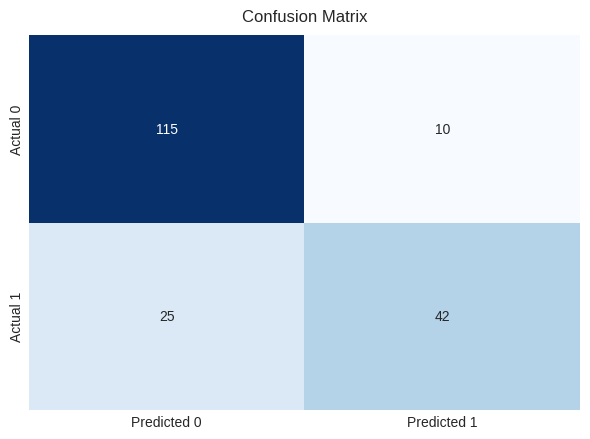

Detailed Classification Report:

                  precision    recall  f1-score   support

Non-Diabetic (0)       0.82      0.92      0.87       125
    Diabetic (1)       0.81      0.63      0.71        67

        accuracy                           0.82       192
       macro avg       0.81      0.77      0.79       192
    weighted avg       0.82      0.82      0.81       192

Accuracy  : 0.8177
Precision : 0.8077
Recall    : 0.6269
F1-Score  : 0.7059


In [6]:
y_pred = logreg.predict(X_test)

# Confusion matrix calculation
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)

# Visualization via Seaborn Heatmap
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(cnf_matrix, annot=True, fmt='g', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'], ax=ax)
ax.set_title("Confusion Matrix", fontsize=12, pad=10)
plt.tight_layout()
plt.show()

# Key Classification Metrics
print("Detailed Classification Report:\n")
print(metrics.classification_report(y_test, y_pred, target_names=['Non-Diabetic (0)', 'Diabetic (1)']))

print(f"Accuracy  : {metrics.accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {metrics.precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {metrics.recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {metrics.f1_score(y_test, y_pred):.4f}")

## 6. ROC Curve & AUC Score
The **Receiver Operating Characteristic (ROC)** curve plots the True Positive Rate (Sensitivity) against the False Positive Rate (1 - Specificity) across all classification thresholds. The **Area Under the Curve (AUC)** measures discrimination capability (1.0 = perfect model, 0.5 = random guessing).

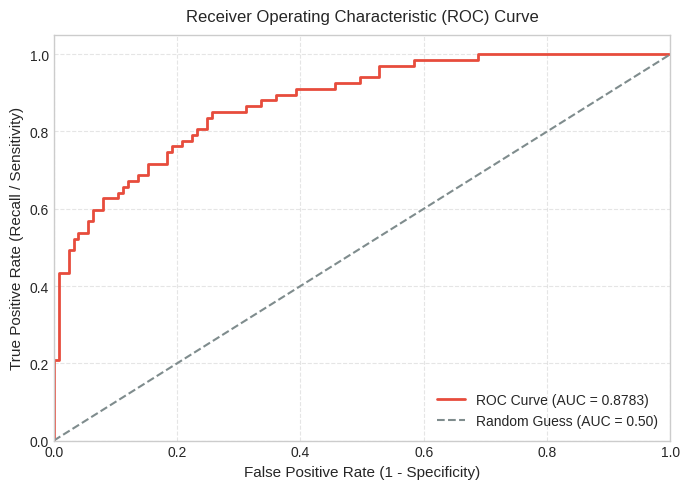

In [7]:
# Predict probabilities for the positive class (class 1)
y_pred_proba = logreg.predict_proba(X_test)[:, 1]

# Calculate ROC points
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred_proba)
auc_score = metrics.roc_auc_score(y_test, y_pred_proba)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='#e74c3c', linewidth=2, label=f"ROC Curve (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], color='#7f8c8d', linestyle='--', label="Random Guess (AUC = 0.50)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=11)
plt.title("Receiver Operating Characteristic (ROC) Curve", fontsize=12, pad=10)
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 7. Single-Patient Inference & Probability Inspection
Pass an individual patient profile into `.predict_proba()` to evaluate how the model translates diagnostic variables into continuous probability outputs.

In [10]:
# Pass sample as a DataFrame with matching column names
sample_patient = pd.DataFrame([[2, 100, 31.5, 33, 140, 72, 0.45]], columns=feature_cols)

# Predict class and probabilities
pred_class = logreg.predict(sample_patient)[0]
pred_prob = logreg.predict_proba(sample_patient)[0]

print("Patient Diagnostic Input :")
display(sample_patient)
print(f"Predicted Diagnosis      : {'Diabetic (1)' if pred_class == 1 else 'Non-Diabetic (0)'}")
print(f"Class Probabilities      : P(Non-Diabetic) = {pred_prob[0]:.2%}, P(Diabetic) = {pred_prob[1]:.2%}")

Patient Diagnostic Input :


,pregnant,insulin,bmi,age,glucose,bp,pedigree
0,2,100,31.5,33,140,72,0.45


Predicted Diagnosis      : Non-Diabetic (0)
Class Probabilities      : P(Non-Diabetic) = 62.74%, P(Diabetic) = 37.26%
